# Hodge-Sinkhorn playground

Minimal checks for the Hodge decomposition + relaxed permutation + existence cone.
Docs: `docs/ideas/ORDER_FACTORIZED_VISION.md`, `docs/ideas/APPENDIX_HODGE_DECOMPOSITION.md`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)


## Hodge decomposition
$A = G + C,\quad r_i = \tfrac{1}{d}\sum_j A_{ij},\quad G_{ij} = r_i - r_j,\quad \|C\|_F^2 = \|A\|_F^2 - 2d\|r\|_2^2$

See `docs/ideas/APPENDIX_HODGE_DECOMPOSITION.md`.


In [2]:
d = 5
r_true = np.arange(d, 0, -1.0)          # node 0 = source (max score), node d-1 = sink
A_dag = r_true[:, None] - r_true[None, :]   # pure gradient flow: zero curl
A_cyc = A_dag.copy()
A_cyc[0, 2], A_cyc[2, 0] = A_dag[2, 0], A_dag[0, 2]  # flip one pair -> 3-cycle 0->1->2->0


DAG |C|_F^2 = 0.0 | closed form = 0.0
CYC |C|_F^2 = 19.2 | closed form = 19.2


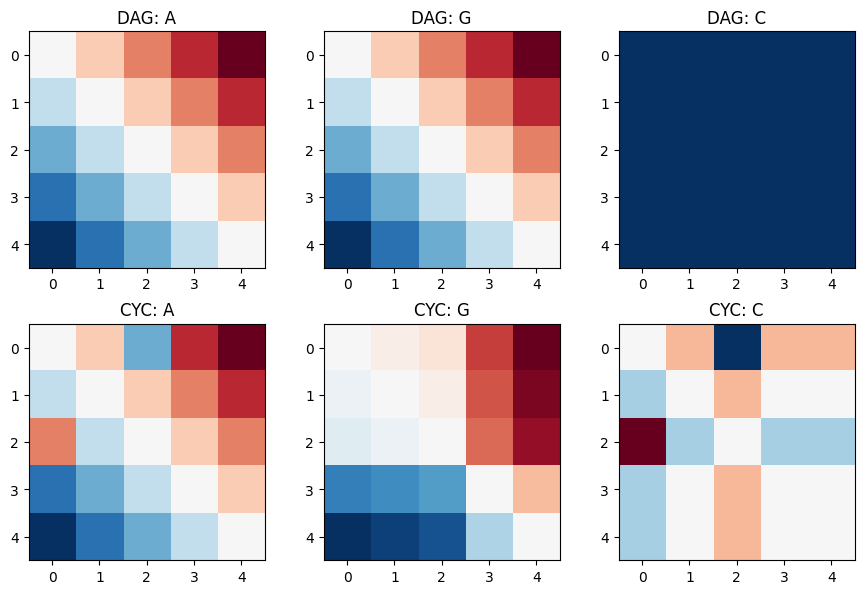

In [3]:
def hodge(A):
    r = A.sum(1) / d                      # closed-form ranking scores (row sums)
    G = r[:, None] - r[None, :]
    return r, G, A - G

for name, A in [("DAG", A_dag), ("CYC", A_cyc)]:
    r, G, C = hodge(A)
    curl2_cf = np.sum(A**2) - 2 * d * np.sum(r**2)   # closed form (r already centered)
    print(name, "|C|_F^2 =", round(np.sum(C**2), 6), "| closed form =", round(curl2_cf, 6))

fig, axs = plt.subplots(2, 3, figsize=(9, 6))
for row, (name, A) in enumerate([("DAG", A_dag), ("CYC", A_cyc)]):
    r, G, C = hodge(A)
    for col, (M, t) in enumerate([(A, "A"), (G, "G"), (C, "C")]):
        axs[row, col].imshow(M, cmap="RdBu_r")
        axs[row, col].set_title(f"{name}: {t}")
plt.tight_layout(); plt.show()


## Relaxed permutation
$P_\sigma = \mathrm{Sinkhorn}_\tau(r + \varepsilon),\quad \varepsilon \sim \mathrm{Gumbel}(0,1)$

See `docs/ideas/ORDER_FACTORIZED_VISION.md` section 3.


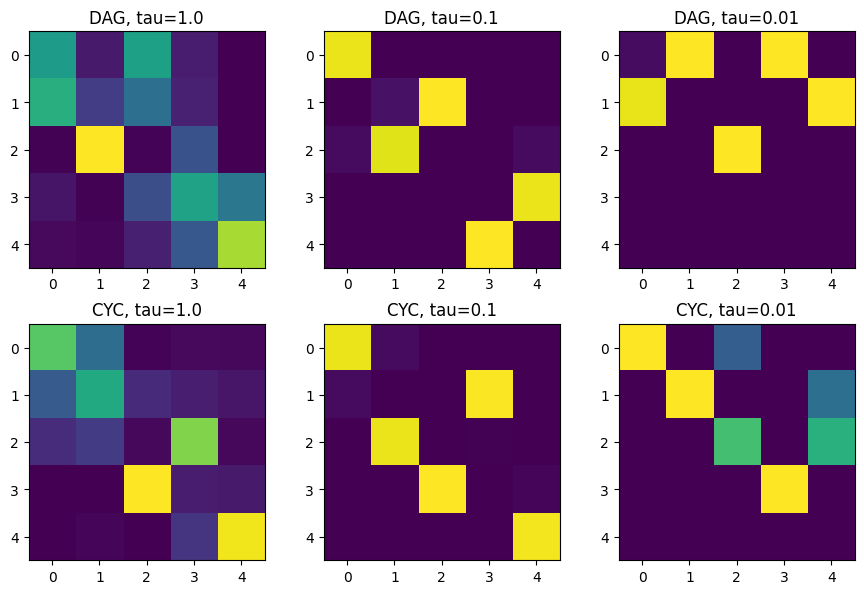

In [4]:
pos = np.arange(d, 0, -1.0)             # position weights: earlier position = higher utility

def sinkhorn(r, tau, n_iter=30):
    S = (r[:, None] * pos[None, :] + rng.gumbel(size=(d, d))) / tau
    P = np.exp(S - S.max())
    for _ in range(n_iter):
        P /= P.sum(1, keepdims=True) + 1e-300
        P /= P.sum(0, keepdims=True) + 1e-300
    return P                             # P[i, k] = P(node i at position k)

fig, axs = plt.subplots(2, 3, figsize=(9, 6))
for row, (name, A) in enumerate([("DAG", A_dag), ("CYC", A_cyc)]):
    r, _, _ = hodge(A)
    for col, tau in enumerate([1.0, 0.1, 0.01]):
        axs[row, col].imshow(sinkhorn(r, tau), cmap="viridis")
        axs[row, col].set_title(f"{name}, tau={tau}")
plt.tight_layout(); plt.show()


## Existence cone
$\mathrm{allowed}(i\!\to\!j) = [P_\sigma^{\top} T P_\sigma]_{ij},\quad T$ strictly upper-triangular.

See `docs/ideas/ORDER_FACTORIZED_VISION.md` section 3, step 3.


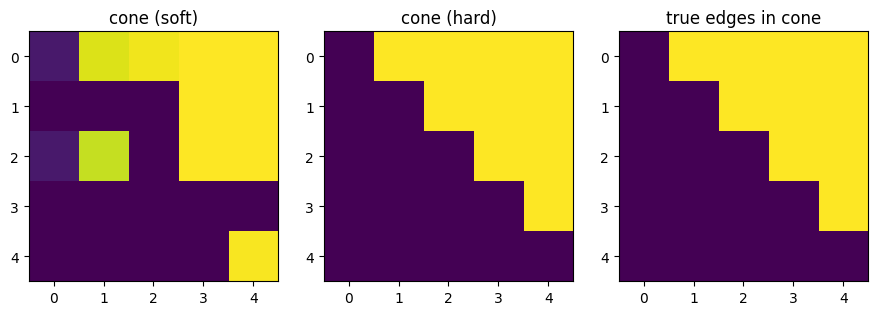

In [5]:
T = np.triu(np.ones((d, d)), 1)         # strictly upper-triangular cone template
r, _, _ = hodge(A_dag)
cone_soft = sinkhorn(r, 0.1).T @ T @ sinkhorn(r, 0.1)

P_hard = np.zeros((d, d))               # hard assignment from argsort(-r)
for k, i in enumerate(np.argsort(-r)):
    P_hard[i, k] = 1
cone_hard = P_hard.T @ T @ P_hard

fig, axs = plt.subplots(1, 3, figsize=(9, 3))
for ax, M, t in zip(axs, [cone_soft, cone_hard, cone_hard * (A_dag > 0)],
                    ["cone (soft)", "cone (hard)", "true edges in cone"]):
    ax.imshow(M, cmap="viridis")
    ax.set_title(t)
plt.tight_layout(); plt.show()


## Sampled graphs
$z_{ij} \sim \mathrm{Bernoulli}(p_{ij})$ inside the cone only: $q(z_{ij}\,|\,\sigma) \propto z_{ij}\,\mathrm{allowed}(i\!\to\!j)$.


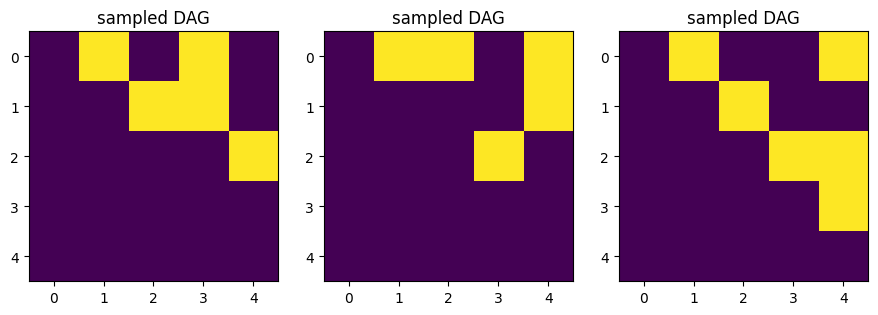

In [6]:
p = 0.5 * np.ones((d, d))               # placeholder existence marginals
fig, axs = plt.subplots(1, 3, figsize=(9, 3))
for ax in axs:
    Z = (rng.random((d, d)) < p) * cone_hard
    ax.imshow(Z, cmap="viridis")
    ax.set_title("sampled DAG")
plt.tight_layout(); plt.show()


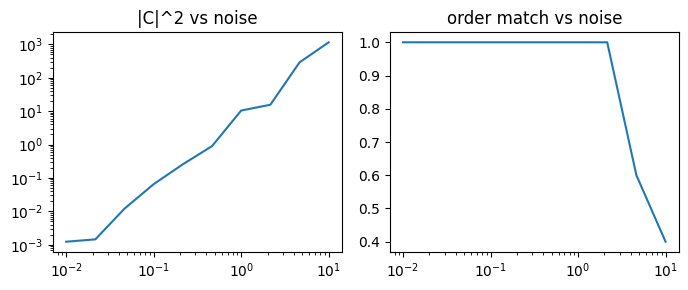

In [7]:
scales = np.logspace(-2, 1, 10)
curls, match = [], []
for s in scales:
    A_n = A_dag + rng.normal(scale=s, size=(d, d))
    A_n = (A_n - A_n.T) / 2             # project back to antisymmetric
    r_n, _, C_n = hodge(A_n)
    curls.append(np.sum(C_n**2))
    match.append(np.mean(np.argsort(-r_n) == np.argsort(-r)))  # position match vs true order

fig, axs = plt.subplots(1, 2, figsize=(7, 3))
axs[0].loglog(scales, curls); axs[0].set_title("|C|^2 vs noise")
axs[1].semilogx(scales, match); axs[1].set_title("order match vs noise")
plt.tight_layout(); plt.show()
